In [1]:
s# ============================================================
# EXPERIMENT 7 - AUTOENCODERS, CAE, DENOISING AE AND VAE
# CELL 1: SETUP + DATA + COMMON FUNCTIONS
# ============================================================

import os
import time
import shutil
import zipfile
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from pathlib import Path
from tensorflow import keras
from tensorflow.keras import layers, Model
from skimage.metrics import structural_similarity as ssim
from IPython.display import display

# -----------------------------
# Reproducibility
# -----------------------------
SEED = 42
np.random.seed(SEED)
tf.random.set_seed(SEED)
random.seed(SEED)

# -----------------------------
# Output folders
# -----------------------------
OUT = Path("/content/experiment7_results")
GRAPH_DIR = OUT / "graphs"
TABLE_DIR = OUT / "tables"

if OUT.exists():
    shutil.rmtree(OUT)

GRAPH_DIR.mkdir(parents=True)
TABLE_DIR.mkdir(parents=True)

print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU"))

# -----------------------------
# Runtime settings
# -----------------------------
GPU_AVAILABLE = len(tf.config.list_physical_devices("GPU")) > 0

# Main experiment follows the manual when GPU is available.
# On CPU, slightly smaller settings prevent excessive runtime.
if GPU_AVAILABLE:
    MAIN_EPOCHS_FC = 20
    MAIN_EPOCHS_CAE = 15
    MAIN_EPOCHS_DAE = 12
    MAIN_EPOCHS_VAE = 15
else:
    MAIN_EPOCHS_FC = 15
    MAIN_EPOCHS_CAE = 10
    MAIN_EPOCHS_DAE = 8
    MAIN_EPOCHS_VAE = 10

BATCH_SIZE = 128

# Additional experiments deliberately use a smaller subset
# and fewer epochs so everything remains under a practical runtime.
ADD_TRAIN_N = 5000
ADD_TEST_N = 1000
ADD_EPOCHS = 3

# -----------------------------
# Load MNIST
# -----------------------------
(x_train_full, y_train_full), (x_test_full, y_test_full) = \
    keras.datasets.mnist.load_data()

x_train = x_train_full[:10000].astype("float32") / 255.0
y_train = y_train_full[:10000]

x_test = x_test_full[:2000].astype("float32") / 255.0
y_test = y_test_full[:2000]

x_train = x_train[..., np.newaxis]
x_test = x_test[..., np.newaxis]

print("Training shape:", x_train.shape)
print("Test shape:", x_test.shape)

# -----------------------------
# Plot / save helper
# -----------------------------
def save_fig(name, dpi=600):
    plt.tight_layout()
    plt.savefig(GRAPH_DIR / f"{name}.png", dpi=150, bbox_inches="tight")
    plt.savefig(GRAPH_DIR / f"{name}.eps", dpi=dpi, bbox_inches="tight")
    plt.show()
    plt.close()

# -----------------------------
# Training history plot helper
# -----------------------------
def plot_history(history, title, filename):
    plt.figure(figsize=(7, 5))
    plt.plot(history.history["loss"], label="Training Loss")
    if "val_loss" in history.history:
        plt.plot(history.history["val_loss"], label="Validation Loss")
    plt.xlabel("Epoch")
    plt.ylabel("Reconstruction Loss")
    plt.title(title)
    plt.legend()
    save_fig(filename)

# -----------------------------
# Metrics
# -----------------------------
def reconstruction_metrics(original, reconstructed):
    original = np.asarray(original)
    reconstructed = np.asarray(reconstructed)

    mse = float(np.mean((original - reconstructed) ** 2))
    mae = float(np.mean(np.abs(original - reconstructed)))

    ssim_values = []
    for i in range(len(original)):
        s = ssim(
            original[i].squeeze(),
            reconstructed[i].squeeze(),
            data_range=1.0
        )
        ssim_values.append(s)

    return mse, mae, float(np.mean(ssim_values))

# -----------------------------
# Per-image reconstruction error
# -----------------------------
def per_image_error(original, reconstructed):
    return np.mean(
        (original - reconstructed) ** 2,
        axis=(1, 2, 3)
    )

# -----------------------------
# Parameter + timing helper
# -----------------------------
def train_model(model, x, validation_data,
                epochs, batch_size=BATCH_SIZE,
                verbose=1):

    start = time.time()

    history = model.fit(
        x,
        x if not isinstance(x, tuple) else x[1],
        validation_data=validation_data,
        epochs=epochs,
        batch_size=batch_size,
        shuffle=True,
        verbose=verbose
    )

    elapsed = time.time() - start

    return history, elapsed

# -----------------------------
# Image grid helper
# -----------------------------
def image_grid(images, titles=None, rows=2, cols=5,
               figsize=(12, 5), filename=None):

    plt.figure(figsize=figsize)

    for i in range(min(len(images), rows * cols)):
        ax = plt.subplot(rows, cols, i + 1)
        ax.imshow(images[i].squeeze(), cmap="gray")
        ax.axis("off")

        if titles is not None:
            ax.set_title(titles[i], fontsize=9)

    if filename:
        save_fig(filename)
    else:
        plt.tight_layout()
        plt.show()
        plt.close()

print("Setup complete.")

TensorFlow: 2.20.0
GPU: []
11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
Training shape: (10000, 28, 28, 1)
Test shape: (2000, 28, 28, 1)
Setup complete.



========== FULLY CONNECTED AE ==========


Model: "FullyConnectedAE"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 32)             │         4,128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Dense)                  │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 32)             │           544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 128)            │         4,224 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 784)            │       101,136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 28, 28, 1)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 211,040 (824.38 KB)

 Trainable params: 211,040 (824.38 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 7s 35ms/step - loss: 0.3442 - val_loss: 0.2423
Epoch 2/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 28ms/step - loss: 0.2255 - val_loss: 0.2035
Epoch 3/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.1899 - val_loss: 0.1784
Epoch 4/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 2s 20ms/step - loss: 0.1715 - val_loss: 0.1655
Epoch 5/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1596 - val_loss: 0.1560
Epoch 6/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1518 - val_loss: 0.1497
Epoch 7/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1463 - val_loss: 0.1458
Epoch 8/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.1424 - val_loss: 0.1427
Epoch 9/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1392 - val_loss: 0.1400
Epoch 10/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1364 - val_loss: 0.1377
Epoch 11/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1341 - val_loss: 0.1354
Epoch 12/15
79/79 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.1

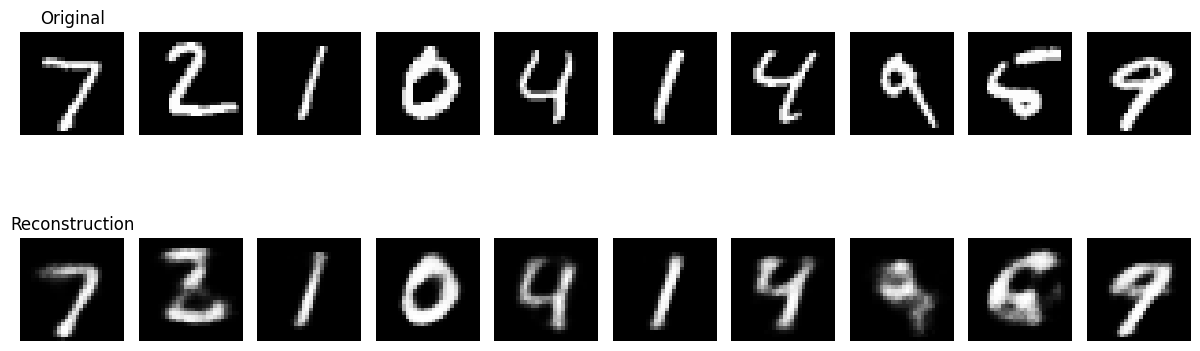

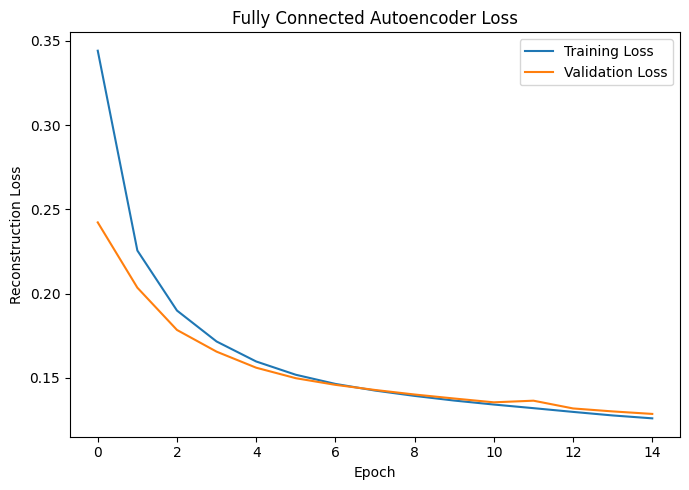


========== CONVOLUTIONAL AE ==========


Model: "CAE_64"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 28, 28, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 28, 28, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 14, 14, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 14, 14, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ latent (Conv2D)                 │ (None, 7, 7, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d (UpSampling2D)    │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 32)     │        18,464 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ up_sampling2d_1 (UpSampling2D)  │ (None, 28, 28, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 28, 28, 1)      │           289 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 74,497 (291.00 KB)

 Trainable params: 74,497 (291.00 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 376ms/step - loss: 0.2463 - val_loss: 0.1027
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 29s 371ms/step - loss: 0.0924 - val_loss: 0.0838
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 387ms/step - loss: 0.0829 - val_loss: 0.0786
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 393ms/step - loss: 0.0795 - val_loss: 0.0757
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 29s 373ms/step - loss: 0.0763 - val_loss: 0.0738
Epoch 6/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 29s 371ms/step - loss: 0.0747 - val_loss: 0.0727
Epoch 7/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 373ms/step - loss: 0.0735 - val_loss: 0.0715
Epoch 8/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 43s 396ms/step - loss: 0.0726 - val_loss: 0.0709
Epoch 9/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 374ms/step - loss: 0.0719 - val_loss: 0.0701
Epoch 10/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 372ms/step - loss: 0.0712 - val_loss: 0.0696


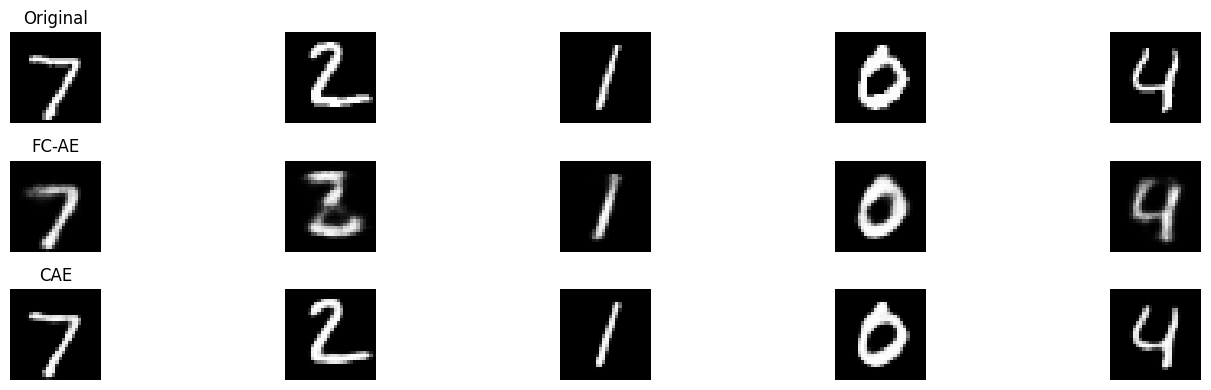

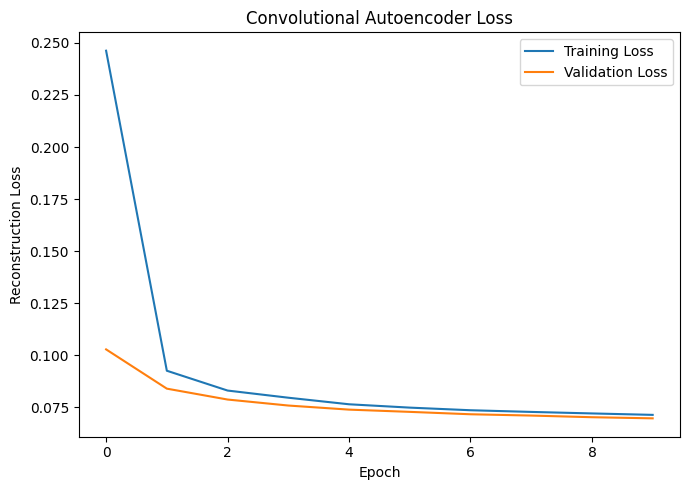


========== DENOISING CAE ==========
Epoch 1/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 33s 404ms/step - loss: 0.4149 - val_loss: 0.1892
Epoch 2/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 380ms/step - loss: 0.3351 - val_loss: 0.1695
Epoch 3/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 381ms/step - loss: 0.3246 - val_loss: 0.1642
Epoch 4/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 381ms/step - loss: 0.3195 - val_loss: 0.1581
Epoch 5/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 31s 397ms/step - loss: 0.3150 - val_loss: 0.1546
Epoch 6/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 30s 381ms/step - loss: 0.3124 - val_loss: 0.1518
Epoch 7/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 381ms/step - loss: 0.3100 - val_loss: 0.1500
Epoch 8/8
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 381ms/step - loss: 0.3079 - val_loss: 0.1494

========== GAUSSIAN NOISE RESULTS ==========


,Noise Level,MSE,MAE,SSIM
0,0.1,0.007502,0.059067,0.664982
1,0.2,0.014070,0.094284,0.600739
2,0.3,0.024189,0.129131,0.544876


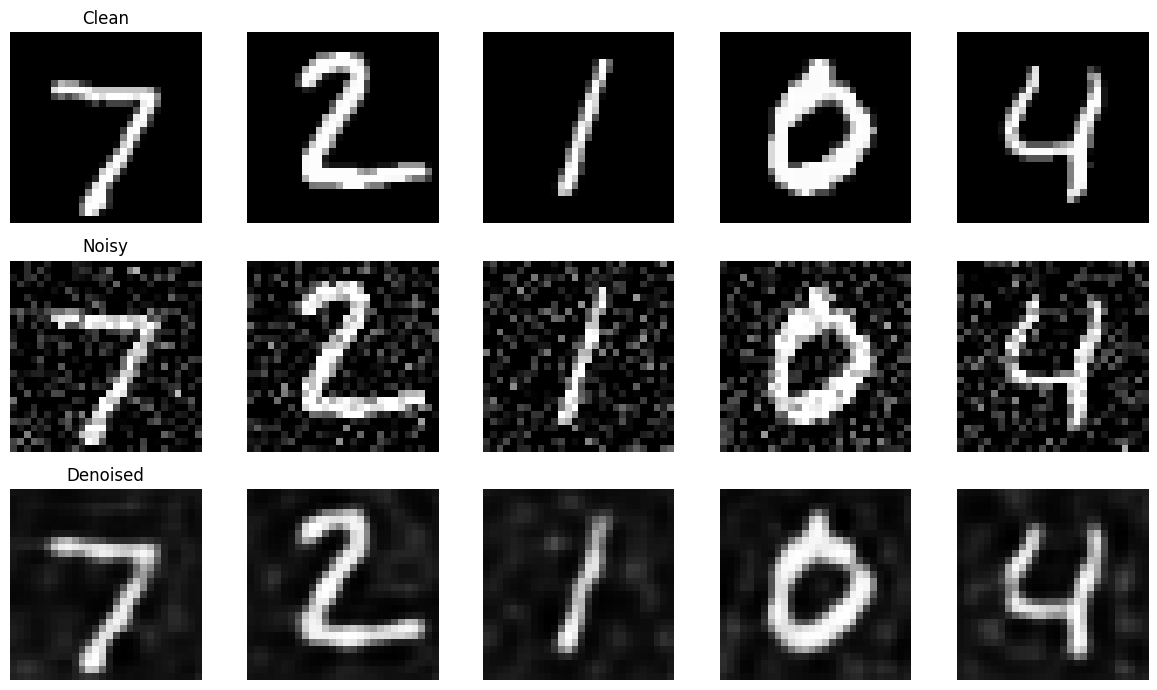

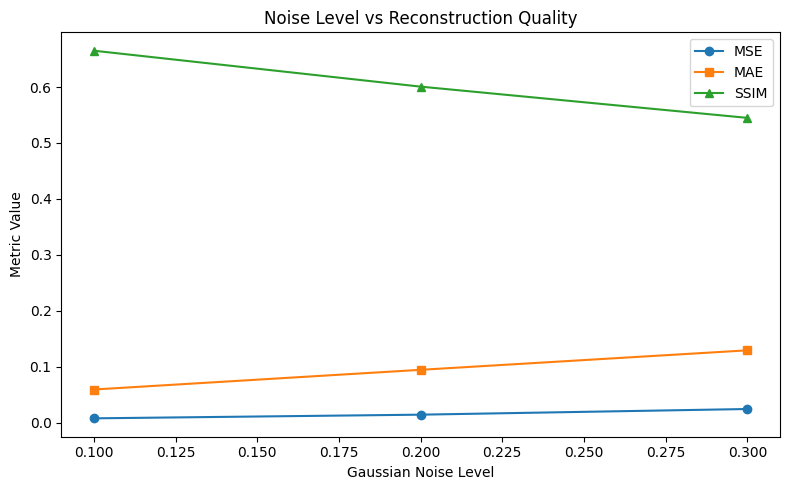


========== RECONSTRUCTION COMPARISON ==========


,Model,MSE,MAE,SSIM,Parameters,Training Time (s)
0,Fully Connected AE,0.022454,0.058811,0.731017,211040,23.804148
1,Convolutional AE,0.003355,0.017342,0.966246,74497,346.914798
2,Denoising CAE,0.014070,0.094284,0.600739,74497,278.027609



========== ALL MAIN TABLES SO FAR ==========


,Noise Level,MSE,MAE,SSIM
0,0.1,0.007502,0.059067,0.664982
1,0.2,0.014070,0.094284,0.600739
2,0.3,0.024189,0.129131,0.544876


,Model,MSE,MAE,SSIM,Parameters,Training Time (s)
0,Fully Connected AE,0.022454,0.058811,0.731017,211040,23.804148
1,Convolutional AE,0.003355,0.017342,0.966246,74497,346.914798
2,Denoising CAE,0.014070,0.094284,0.600739,74497,278.027609


In [2]:
# ============================================================
# CELL 2: FULLY CONNECTED AE + CONVOLUTIONAL AE + DENOISING AE
# ============================================================

# ============================================================
# 1. FULLY CONNECTED AUTOENCODER
# ============================================================

fc_input = keras.Input(shape=(28, 28, 1))

x = layers.Flatten()(fc_input)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dense(32, activation="relu")(x)
fc_latent = layers.Dense(16, activation="relu", name="latent")(x)

x = layers.Dense(32, activation="relu")(fc_latent)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dense(784, activation="sigmoid")(x)
fc_output = layers.Reshape((28, 28, 1))(x)

fc_ae = Model(fc_input, fc_output, name="FullyConnectedAE")

fc_ae.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy"
)

print("\n========== FULLY CONNECTED AE ==========")
fc_ae.summary()

fc_history, fc_time = train_model(
    fc_ae,
    x_train,
    validation_data=(x_test, x_test),
    epochs=MAIN_EPOCHS_FC
)

fc_recon = fc_ae.predict(x_test, batch_size=BATCH_SIZE, verbose=0)

fc_mse, fc_mae, fc_ssim = reconstruction_metrics(
    x_test, fc_recon
)

# Plot 1 - Original vs Reconstruction
idx = np.arange(10)

plt.figure(figsize=(12, 5))

for i, j in enumerate(idx):
    ax = plt.subplot(2, 10, i + 1)
    ax.imshow(x_test[j].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("Original")

    ax = plt.subplot(2, 10, i + 11)
    ax.imshow(fc_recon[j].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("Reconstruction")

save_fig("01_original_vs_fc_reconstruction")

# Plot 2 - FC training / validation loss
plot_history(
    fc_history,
    "Fully Connected Autoencoder Loss",
    "02_fc_training_validation_loss"
)


# ============================================================
# 2. CONVOLUTIONAL AUTOENCODER
# ============================================================

def build_cae(latent_channels=64):
    inp = keras.Input(shape=(28, 28, 1))

    x = layers.Conv2D(
        32, 3, activation="relu", padding="same"
    )(inp)
    x = layers.MaxPooling2D(2, padding="same")(x)

    x = layers.Conv2D(
        64, 3, activation="relu", padding="same"
    )(x)
    x = layers.MaxPooling2D(2, padding="same")(x)

    latent = layers.Conv2D(
        latent_channels, 3,
        activation="relu",
        padding="same",
        name="latent"
    )(x)

    x = layers.UpSampling2D(2)(latent)
    x = layers.Conv2D(
        32, 3, activation="relu", padding="same"
    )(x)

    x = layers.UpSampling2D(2)(x)

    out = layers.Conv2D(
        1, 3, activation="sigmoid", padding="same"
    )(x)

    return Model(inp, out, name=f"CAE_{latent_channels}")


cae = build_cae(64)

cae.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy"
)

print("\n========== CONVOLUTIONAL AE ==========")
cae.summary()

cae_history, cae_time = train_model(
    cae,
    x_train,
    validation_data=(x_test, x_test),
    epochs=MAIN_EPOCHS_CAE
)

cae_recon = cae.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

cae_mse, cae_mae, cae_ssim = reconstruction_metrics(
    x_test, cae_recon
)

# Plot 3 - FC AE vs CAE
plt.figure(figsize=(15, 4))

for i in range(5):

    ax = plt.subplot(3, 5, i + 1)
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("Original")

    ax = plt.subplot(3, 5, i + 6)
    ax.imshow(fc_recon[i].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("FC-AE")

    ax = plt.subplot(3, 5, i + 11)
    ax.imshow(cae_recon[i].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("CAE")

save_fig("03_fc_vs_cae_reconstruction")

plot_history(
    cae_history,
    "Convolutional Autoencoder Loss",
    "04_cae_training_validation_loss"
)


# ============================================================
# 3. DENOISING CONVOLUTIONAL AUTOENCODER
# ============================================================

def gaussian_noise(images, sigma):
    noisy = images + np.random.normal(
        0, sigma, images.shape
    ).astype("float32")
    return np.clip(noisy, 0, 1)


def salt_pepper_noise(images, p):
    noisy = images.copy()

    rand = np.random.rand(*images.shape)

    noisy[rand < p / 2] = 0
    noisy[(rand >= p / 2) & (rand < p)] = 1

    return noisy


# Training corruption:
# random Gaussian sigma between 0.1 and 0.3
def make_denoising_training_data(images):
    noisy = np.empty_like(images)

    for i in range(len(images)):
        sigma = np.random.uniform(0.1, 0.3)
        noisy[i] = gaussian_noise(
            images[i:i+1], sigma
        )[0]

    return noisy


x_train_noisy = make_denoising_training_data(x_train)

dae = build_cae(64)

dae.compile(
    optimizer=keras.optimizers.Adam(1e-3),
    loss="binary_crossentropy"
)

print("\n========== DENOISING CAE ==========")

dae_history, dae_time = train_model(
    dae,
    x_train_noisy,
    validation_data=(gaussian_noise(x_test, 0.2), x_test),
    epochs=MAIN_EPOCHS_DAE
)

# Evaluation at Gaussian noise levels
noise_results = []

for sigma in [0.1, 0.2, 0.3]:

    noisy_test = gaussian_noise(x_test, sigma)

    denoised = dae.predict(
        noisy_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    mse, mae, ssim_value = reconstruction_metrics(
        x_test, denoised
    )

    noise_results.append([
        sigma, mse, mae, ssim_value
    ])

noise_df = pd.DataFrame(
    noise_results,
    columns=["Noise Level", "MSE", "MAE", "SSIM"]
)

print("\n========== GAUSSIAN NOISE RESULTS ==========")
display(noise_df)

noise_df.to_csv(
    TABLE_DIR / "01_noise_level_results.csv",
    index=False
)

# Plot 4 - Clean / noisy / denoised
noisy_demo = gaussian_noise(x_test[:5], 0.2)
denoised_demo = dae.predict(
    noisy_demo,
    verbose=0
)

plt.figure(figsize=(12, 7))

for i in range(5):

    ax = plt.subplot(3, 5, i + 1)
    ax.imshow(x_test[i].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("Clean")

    ax = plt.subplot(3, 5, i + 6)
    ax.imshow(noisy_demo[i].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("Noisy")

    ax = plt.subplot(3, 5, i + 11)
    ax.imshow(denoised_demo[i].squeeze(), cmap="gray")
    ax.axis("off")
    if i == 0:
        ax.set_title("Denoised")

save_fig("05_clean_noisy_denoised")

# Plot 5 - Noise level vs metrics
plt.figure(figsize=(8, 5))

plt.plot(
    noise_df["Noise Level"],
    noise_df["MSE"],
    marker="o",
    label="MSE"
)

plt.plot(
    noise_df["Noise Level"],
    noise_df["MAE"],
    marker="s",
    label="MAE"
)

plt.plot(
    noise_df["Noise Level"],
    noise_df["SSIM"],
    marker="^",
    label="SSIM"
)

plt.xlabel("Gaussian Noise Level")
plt.ylabel("Metric Value")
plt.title("Noise Level vs Reconstruction Quality")
plt.legend()

save_fig("06_noise_level_vs_quality")


# ============================================================
# BASIC METRIC TABLES
# ============================================================

basic_results = pd.DataFrame([
    [
        "Fully Connected AE",
        fc_mse,
        fc_mae,
        fc_ssim,
        fc_ae.count_params(),
        fc_time
    ],
    [
        "Convolutional AE",
        cae_mse,
        cae_mae,
        cae_ssim,
        cae.count_params(),
        cae_time
    ],
    [
        "Denoising CAE",
        noise_df.loc[
            noise_df["Noise Level"] == 0.2, "MSE"
        ].iloc[0],
        noise_df.loc[
            noise_df["Noise Level"] == 0.2, "MAE"
        ].iloc[0],
        noise_df.loc[
            noise_df["Noise Level"] == 0.2, "SSIM"
        ].iloc[0],
        dae.count_params(),
        dae_time
    ]
], columns=[
    "Model",
    "MSE",
    "MAE",
    "SSIM",
    "Parameters",
    "Training Time (s)"
])

print("\n========== RECONSTRUCTION COMPARISON ==========")
display(basic_results)

basic_results.to_csv(
    TABLE_DIR / "02_reconstruction_comparison.csv",
    index=False
)

print("\n========== ALL MAIN TABLES SO FAR ==========")
display(noise_df)
display(basic_results)

Model: "encoder"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 28, 28, 1) │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_11 (Conv2D)  │ (None, 28, 28,    │        320 │ encoder_input[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 14, 14,    │          0 │ conv2d_11[0][0]   │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_12 (Conv2D)  │ (None, 14, 14,    │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 7, 7, 64)  │          0 │ conv2d_12[0][0]   │
│ (MaxPooling2D)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ flatten_2 (Flatten) │ (None, 3136)      │          0 │ max_pooling2d_5[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 128)       │    401,536 │ flatten_2[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_mean (Dense)      │ (None, 2)         │        258 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ z_log_var (Dense)   │ (None, 2)         │        258 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ sampling (Sampling) │ (None, 2)         │          0 │ z_mean[0][0],     │
│                     │                   │            │ z_log_var[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 420,868 (1.61 MB)

 Trainable params: 420,868 (1.61 MB)

 Non-trainable params: 0 (0.00 B)

Model: "decoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ z_sampling (InputLayer)         │ (None, 2)              │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_10 (Dense)                │ (None, 3136)           │         9,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_2 (Reshape)             │ (None, 7, 7, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 14, 14, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 28, 28, 32)     │        18,464 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 28, 28, 1)      │           289 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 65,089 (254.25 KB)

 Trainable params: 65,089 (254.25 KB)

 Non-trainable params: 0 (0.00 B)


Training VAE...
Epoch 1/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 37s 310ms/step - kl_loss: 5.8640 - loss: 270.1870 - reconstruction_loss: 264.3230 - val_kl_loss: 5.0904 - val_loss: 196.0787 - val_reconstruction_loss: 190.9883
Epoch 2/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 305ms/step - kl_loss: 3.8326 - loss: 194.1791 - reconstruction_loss: 190.3465 - val_kl_loss: 4.3452 - val_loss: 178.9431 - val_reconstruction_loss: 174.5979
Epoch 3/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 306ms/step - kl_loss: 4.4085 - loss: 180.3710 - reconstruction_loss: 175.9625 - val_kl_loss: 4.5631 - val_loss: 171.4640 - val_reconstruction_loss: 166.9010
Epoch 4/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 24s 307ms/step - kl_loss: 4.5677 - loss: 175.6273 - reconstruction_loss: 171.0597 - val_kl_loss: 4.6277 - val_loss: 169.2493 - val_reconstruction_loss: 164.6215
Epoch 5/10
79/79 ━━━━━━━━━━━━━━━━━━━━ 41s 307ms/step - kl_loss: 4.6475 - loss: 173.2939 - reconstruction_loss: 168.6463 - val_kl_loss: 4.9845 - val_loss: 167.7806 - val_reconstruction_los

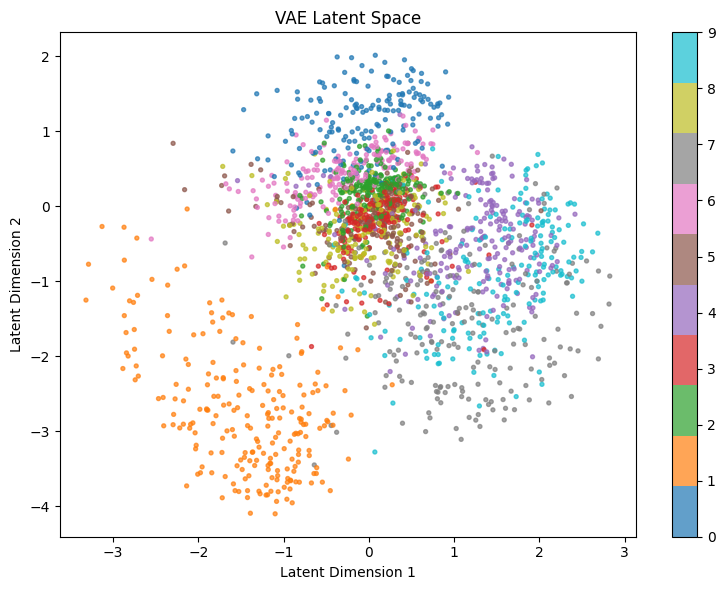

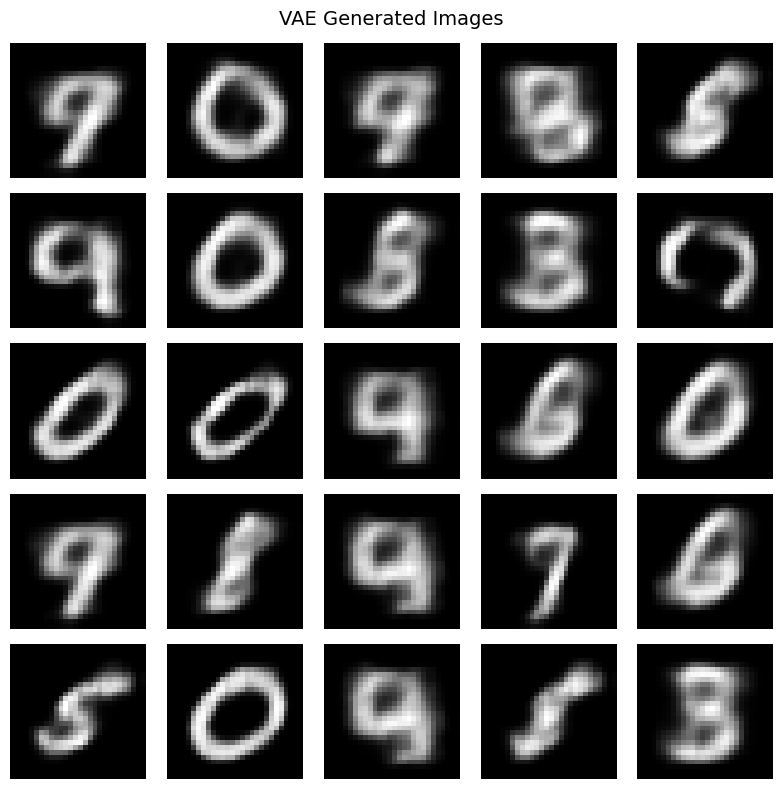

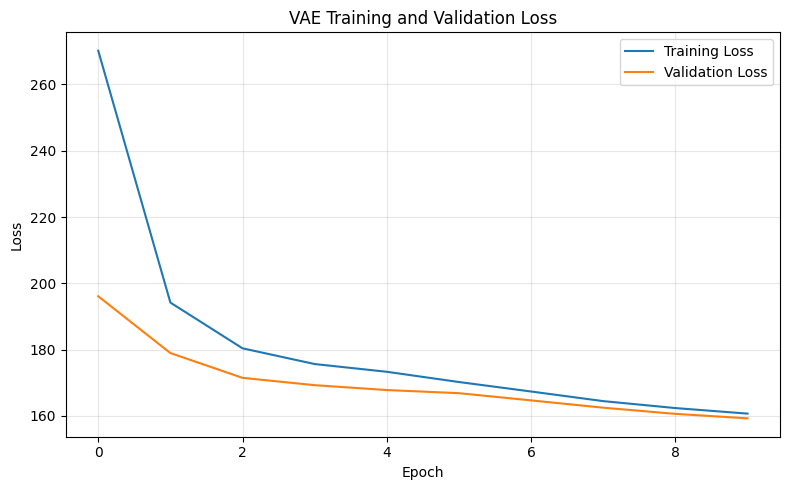

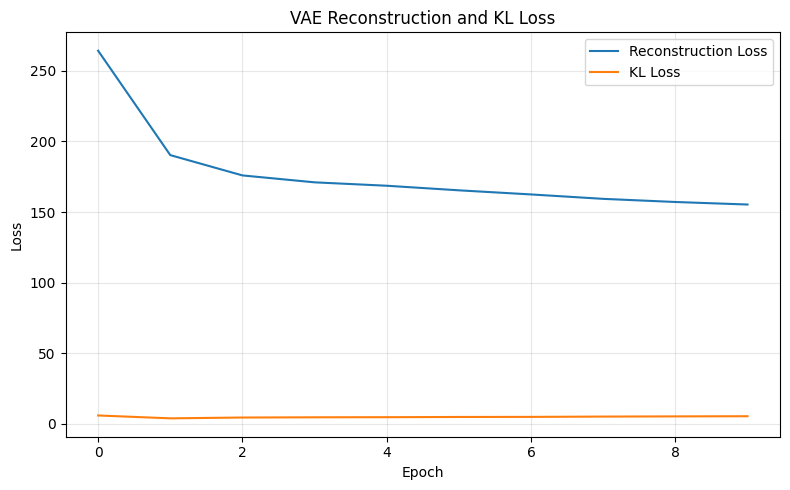

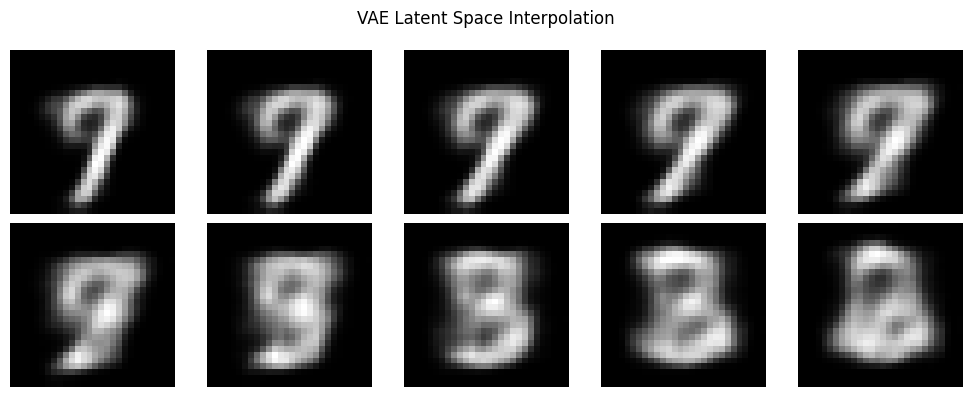

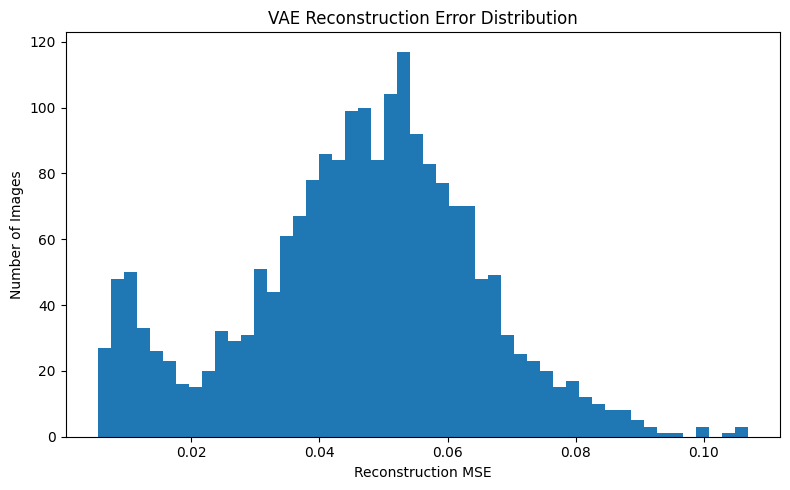

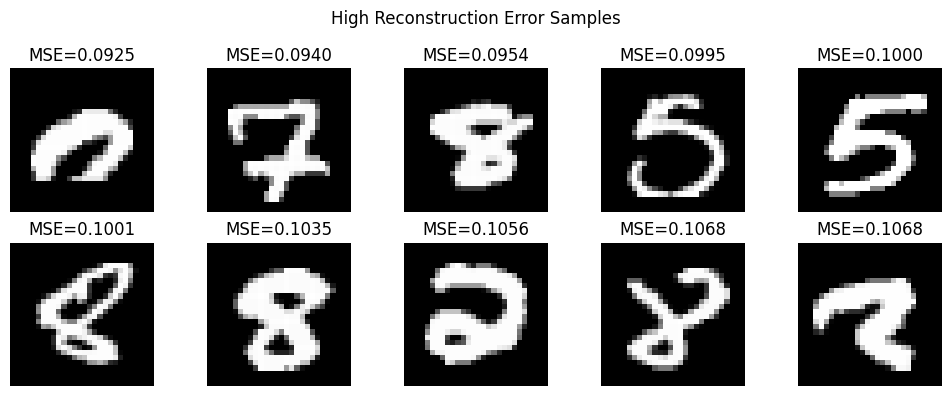


VAE Metrics:


,Metric,Value
0,Latent Dimension,2.000000
1,Final Training Loss,160.665329
2,Final Validation Loss,159.241791
3,Final Reconstruction Loss,155.337402
4,Final KL Loss,5.327906
5,Training Time (s),355.296835



VAE section completed successfully.
All VAE plots saved to: /content/experiment7_results/graphs


In [4]:
# ============================================================
# CELL 3 — CORRECTED VAE + REQUIRED VAE PLOTS/METRICS
# ============================================================

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import os
import time

# ------------------------------------------------------------
# VAE PARAMETERS
# ------------------------------------------------------------
latent_dim = 2

# ------------------------------------------------------------
# SAMPLING LAYER
# ------------------------------------------------------------
class Sampling(layers.Layer):
    def call(self, inputs):
        z_mean, z_log_var = inputs

        epsilon = tf.random.normal(
            shape=tf.shape(z_mean)
        )

        return z_mean + tf.exp(0.5 * z_log_var) * epsilon


# ------------------------------------------------------------
# ENCODER
# ------------------------------------------------------------
encoder_inputs = keras.Input(
    shape=(28, 28, 1),
    name="encoder_input"
)

x = layers.Conv2D(
    32, 3,
    activation="relu",
    padding="same"
)(encoder_inputs)

x = layers.MaxPooling2D(2)(x)

x = layers.Conv2D(
    64, 3,
    activation="relu",
    padding="same"
)(x)

x = layers.MaxPooling2D(2)(x)

x = layers.Flatten()(x)

x = layers.Dense(128, activation="relu")(x)

z_mean = layers.Dense(
    latent_dim,
    name="z_mean"
)(x)

z_log_var = layers.Dense(
    latent_dim,
    name="z_log_var"
)(x)

z = Sampling()([z_mean, z_log_var])

encoder = keras.Model(
    encoder_inputs,
    [z_mean, z_log_var, z],
    name="encoder"
)

encoder.summary()


# ------------------------------------------------------------
# DECODER
# ------------------------------------------------------------
latent_inputs = keras.Input(
    shape=(latent_dim,),
    name="z_sampling"
)

x = layers.Dense(
    7 * 7 * 64,
    activation="relu"
)(latent_inputs)

x = layers.Reshape((7, 7, 64))(x)

x = layers.Conv2DTranspose(
    64,
    3,
    strides=2,
    padding="same",
    activation="relu"
)(x)

x = layers.Conv2DTranspose(
    32,
    3,
    strides=2,
    padding="same",
    activation="relu"
)(x)

decoder_outputs = layers.Conv2DTranspose(
    1,
    3,
    padding="same",
    activation="sigmoid"
)(x)

decoder = keras.Model(
    latent_inputs,
    decoder_outputs,
    name="decoder"
)

decoder.summary()


# ------------------------------------------------------------
# CUSTOM VAE MODEL
# ------------------------------------------------------------
class VAE(keras.Model):

    def __init__(
        self,
        encoder,
        decoder,
        beta=1.0,
        **kwargs
    ):
        super().__init__(**kwargs)

        self.encoder = encoder
        self.decoder = decoder
        self.beta = beta

        self.total_loss_tracker = keras.metrics.Mean(
            name="loss"
        )

        self.reconstruction_loss_tracker = keras.metrics.Mean(
            name="reconstruction_loss"
        )

        self.kl_loss_tracker = keras.metrics.Mean(
            name="kl_loss"
        )

    @property
    def metrics(self):
        return [
            self.total_loss_tracker,
            self.reconstruction_loss_tracker,
            self.kl_loss_tracker
        ]

    def train_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        with tf.GradientTape() as tape:

            z_mean, z_log_var, z = self.encoder(
                data,
                training=True
            )

            reconstruction = self.decoder(
                z,
                training=True
            )

            # Reconstruction loss
            reconstruction_loss = tf.reduce_mean(
                tf.reduce_sum(
                    keras.losses.binary_crossentropy(
                        data,
                        reconstruction
                    ),
                    axis=(1, 2)
                )
            )

            # KL divergence
            kl_loss = -0.5 * tf.reduce_mean(
                tf.reduce_sum(
                    1
                    + z_log_var
                    - tf.square(z_mean)
                    - tf.exp(z_log_var),
                    axis=1
                )
            )

            total_loss = (
                reconstruction_loss
                + self.beta * kl_loss
            )

        grads = tape.gradient(
            total_loss,
            self.trainable_weights
        )

        self.optimizer.apply_gradients(
            zip(grads, self.trainable_weights)
        )

        self.total_loss_tracker.update_state(
            total_loss
        )

        self.reconstruction_loss_tracker.update_state(
            reconstruction_loss
        )

        self.kl_loss_tracker.update_state(
            kl_loss
        )

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss":
                self.reconstruction_loss_tracker.result(),
            "kl_loss":
                self.kl_loss_tracker.result()
        }

    def test_step(self, data):

        if isinstance(data, tuple):
            data = data[0]

        z_mean, z_log_var, z = self.encoder(
            data,
            training=False
        )

        reconstruction = self.decoder(
            z,
            training=False
        )

        reconstruction_loss = tf.reduce_mean(
            tf.reduce_sum(
                keras.losses.binary_crossentropy(
                    data,
                    reconstruction
                ),
                axis=(1, 2)
            )
        )

        kl_loss = -0.5 * tf.reduce_mean(
            tf.reduce_sum(
                1
                + z_log_var
                - tf.square(z_mean)
                - tf.exp(z_log_var),
                axis=1
            )
        )

        total_loss = (
            reconstruction_loss
            + self.beta * kl_loss
        )

        self.total_loss_tracker.update_state(
            total_loss
        )

        self.reconstruction_loss_tracker.update_state(
            reconstruction_loss
        )

        self.kl_loss_tracker.update_state(
            kl_loss
        )

        return {
            "loss": self.total_loss_tracker.result(),
            "reconstruction_loss":
                self.reconstruction_loss_tracker.result(),
            "kl_loss":
                self.kl_loss_tracker.result()
        }


# ------------------------------------------------------------
# CREATE + COMPILE VAE
# ------------------------------------------------------------
vae = VAE(
    encoder,
    decoder,
    beta=1.0
)

vae.compile(
    optimizer=keras.optimizers.Adam(
        learning_rate=1e-3
    )
)


# ------------------------------------------------------------
# TRAIN VAE
# ------------------------------------------------------------
vae_epochs = 15 if GPU_AVAILABLE else 10

print("\nTraining VAE...")
start = time.time()

vae_history = vae.fit(
    x_train,
    epochs=vae_epochs,
    batch_size=BATCH_SIZE,
    validation_data=(x_test, None),
    verbose=1
)

vae_time = time.time() - start

print(
    f"\nVAE training completed in "
    f"{vae_time:.2f} seconds"
)


# ============================================================
# PLOT 7 — VAE LATENT SPACE
# ============================================================

z_mean_test, _, _ = encoder.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

plt.figure(figsize=(8, 6))

scatter = plt.scatter(
    z_mean_test[:, 0],
    z_mean_test[:, 1],
    c=y_test,
    cmap="tab10",
    s=8,
    alpha=0.7
)

plt.colorbar(scatter)
plt.xlabel("Latent Dimension 1")
plt.ylabel("Latent Dimension 2")
plt.title("VAE Latent Space")
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/07_vae_latent_space.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PLOT 8 — GENERATED IMAGES
# ============================================================

n_generate = 25

random_latent = np.random.normal(
    size=(n_generate, latent_dim)
)

generated_images = decoder.predict(
    random_latent,
    verbose=0
)

fig, axes = plt.subplots(
    5, 5,
    figsize=(8, 8)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        generated_images[i].squeeze(),
        cmap="gray"
    )

    ax.axis("off")

plt.suptitle(
    "VAE Generated Images",
    fontsize=14
)

plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/08_vae_generated_images.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PLOT 9 — VAE LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    vae_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    vae_history.history["val_loss"],
    label="Validation Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Training and Validation Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/09_vae_loss.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXTRA — VAE RECONSTRUCTION + KL LOSS
# ============================================================

plt.figure(figsize=(8, 5))

plt.plot(
    vae_history.history["reconstruction_loss"],
    label="Reconstruction Loss"
)

plt.plot(
    vae_history.history["kl_loss"],
    label="KL Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("VAE Reconstruction and KL Loss")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/09b_vae_loss_components.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# PLOT 10 — LATENT INTERPOLATION
# ============================================================

idx1 = 0
idx2 = 1

z1 = z_mean_test[idx1]
z2 = z_mean_test[idx2]

steps = 10

interpolated_z = np.array([
    z1 + (z2 - z1) * alpha
    for alpha in np.linspace(0, 1, steps)
])

interpolated_images = decoder.predict(
    interpolated_z,
    verbose=0
)

fig, axes = plt.subplots(
    2,
    5,
    figsize=(10, 4)
)

for i, ax in enumerate(axes.flat):

    ax.imshow(
        interpolated_images[i].squeeze(),
        cmap="gray"
    )

    ax.axis("off")

plt.suptitle(
    "VAE Latent Space Interpolation"
)

plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/10_vae_latent_interpolation.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# RECONSTRUCTION ERROR DISTRIBUTION
# ============================================================

z_mean_all, _, z_all = encoder.predict(
    x_test,
    batch_size=BATCH_SIZE,
    verbose=0
)

vae_reconstructed = decoder.predict(
    z_all,
    batch_size=BATCH_SIZE,
    verbose=0
)

vae_errors = np.mean(
    np.square(
        x_test - vae_reconstructed
    ),
    axis=(1, 2, 3)
)

plt.figure(figsize=(8, 5))

plt.hist(
    vae_errors,
    bins=50
)

plt.xlabel("Reconstruction MSE")
plt.ylabel("Number of Images")
plt.title("VAE Reconstruction Error Distribution")

plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/11_vae_reconstruction_error_distribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# HIGH-ERROR SAMPLES
# ============================================================

high_error_indices = np.argsort(
    vae_errors
)[-10:]

fig, axes = plt.subplots(
    2,
    5,
    figsize=(10, 4)
)

for ax, idx in zip(
    axes.flat,
    high_error_indices
):

    ax.imshow(
        x_test[idx].squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"MSE={vae_errors[idx]:.4f}"
    )

    ax.axis("off")

plt.suptitle(
    "High Reconstruction Error Samples"
)

plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/12_high_error_samples.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# VAE METRICS TABLE
# ============================================================

vae_metrics = pd.DataFrame({
    "Metric": [
        "Latent Dimension",
        "Final Training Loss",
        "Final Validation Loss",
        "Final Reconstruction Loss",
        "Final KL Loss",
        "Training Time (s)"
    ],
    "Value": [
        latent_dim,
        vae_history.history["loss"][-1],
        vae_history.history["val_loss"][-1],
        vae_history.history["reconstruction_loss"][-1],
        vae_history.history["kl_loss"][-1],
        vae_time
    ]
})

print("\nVAE Metrics:")
display(vae_metrics)

vae_metrics.to_csv(
    f"{TABLE_DIR}/vae_metrics.csv",
    index=False
)

print("\nVAE section completed successfully.")
print(f"All VAE plots saved to: {GRAPH_DIR}")

Additional experiment dataset:
Training samples : 5000
Testing samples  : 1000

EXERCISE 1 — CAE LATENT DIMENSION
Training CAE with latent dimension = 4
Training CAE with latent dimension = 8
Training CAE with latent dimension = 16
Training CAE with latent dimension = 32

CAE Latent Dimension Results:


,Latent Dimension,MSE,MAE,SSIM,Training Time (s)
0,4,0.050406,0.116350,0.410650,109.307239
1,8,0.046150,0.106774,0.476621,108.115892
2,16,0.036355,0.087424,0.588047,115.343014
3,32,0.032971,0.081303,0.627659,116.176229


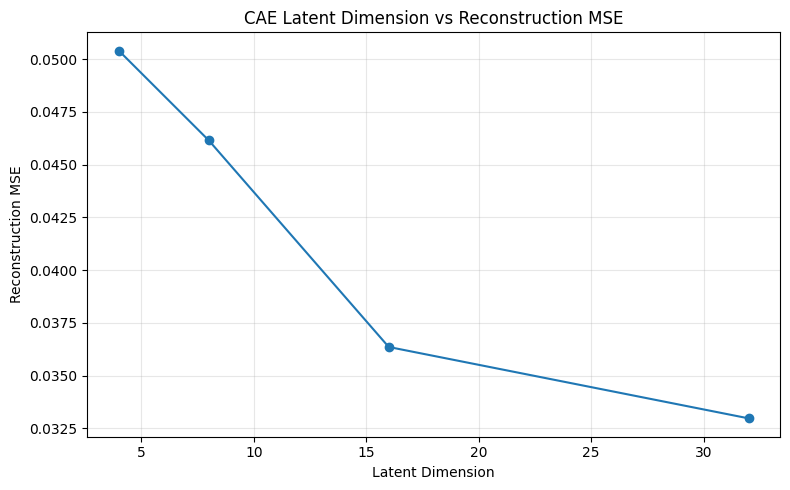

EXERCISE 2 — GAUSSIAN VS SALT-AND-PEPPER NOISE

Noise Type Comparison:


,Noise Type,MSE,MAE,SSIM
0,Gaussian,0.005317,0.023909,0.932470
1,Salt-and-Pepper,0.006924,0.027019,0.919692


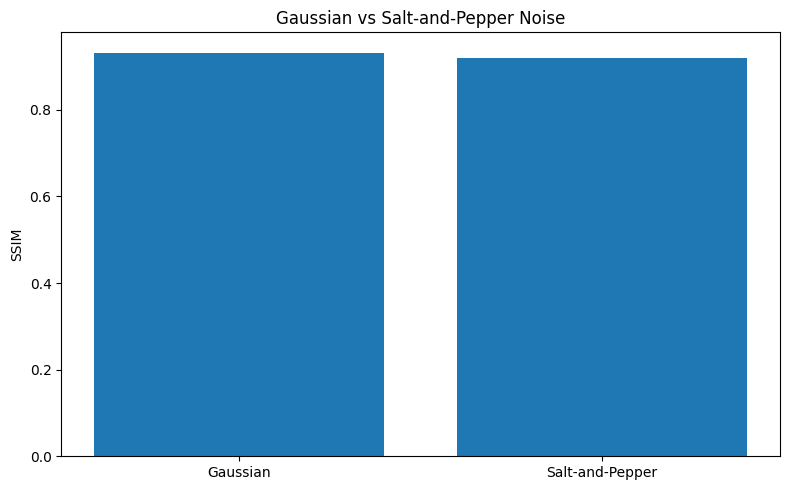

EXERCISE 3 — TWO NOISE LEVELS

Two Noise Level Results:


,Noise Sigma,MSE,MAE,SSIM
0,0.1,0.003592,0.018869,0.957262
1,0.3,0.009129,0.032662,0.884445


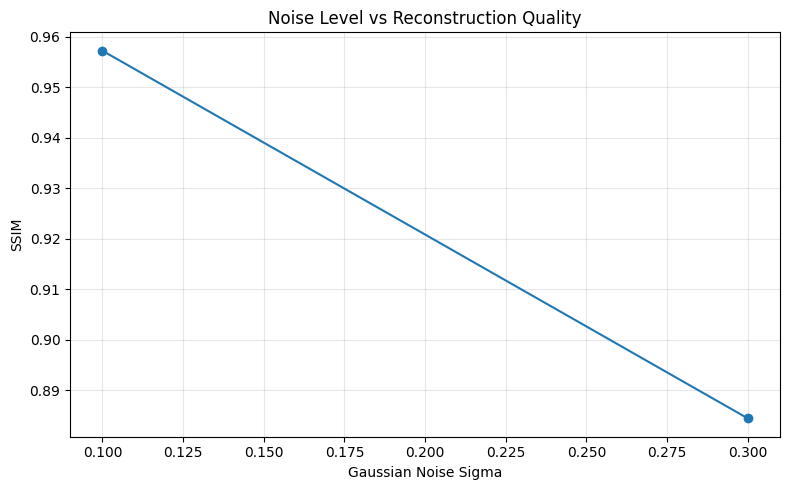

EXERCISE 4 — UPSAMPLING VS CONV2DTRANSPOSE

Decoder Comparison:


,Decoder,MSE,MAE,SSIM,Training Time (s)
0,UpSampling2D + Conv2D,0.007421,0.027869,0.927848,103.054029
1,Conv2DTranspose,0.009176,0.032197,0.905747,48.918783


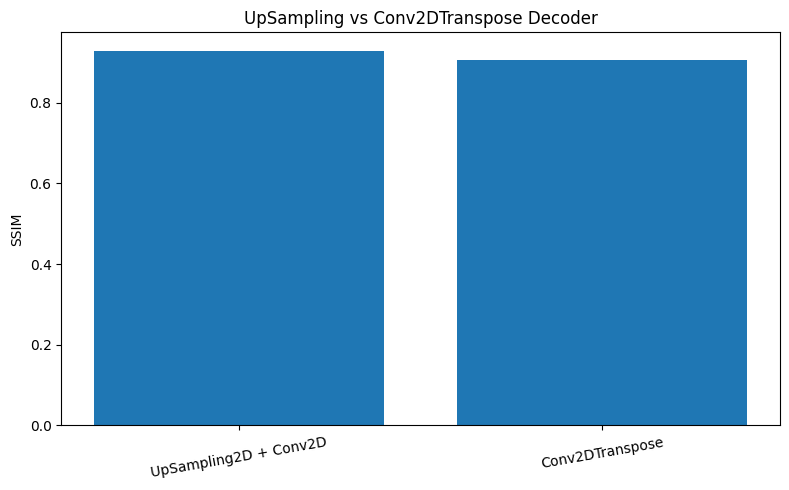

EXERCISE 5 — VAE LATENT DIMENSION 2 VS 8
Training VAE with latent dimension = 2
Training VAE with latent dimension = 8

VAE Latent Dimension Results:


,Latent Dimension,MSE,MAE,SSIM,Training Time (s)
0,2,0.062389,0.141859,0.225166,47.926320
1,8,0.062866,0.144409,0.206582,48.327015


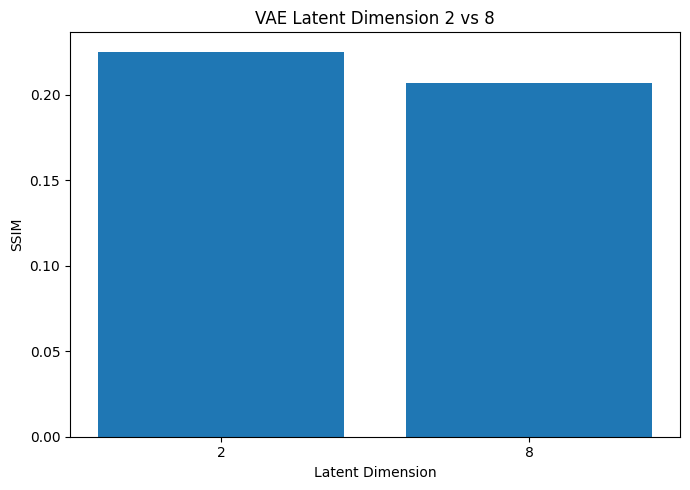

EXERCISE 6 — KL LOSS CONTRIBUTION
Training VAE with KL weight = 0.1
Training VAE with KL weight = 1.0
Training VAE with KL weight = 5.0

KL Weight Results:


,KL Weight,Final Total Loss,Final Reconstruction Loss,Final KL Loss,MSE,MAE,SSIM,Training Time (s)
0,0.1,201.643799,199.989258,16.545380,0.061349,0.140219,0.225465,56.787484
1,1.0,205.325485,201.661652,3.663844,0.061993,0.143074,0.219145,55.892790
2,5.0,207.739594,205.082916,0.531340,0.062941,0.142576,0.212385,64.266596


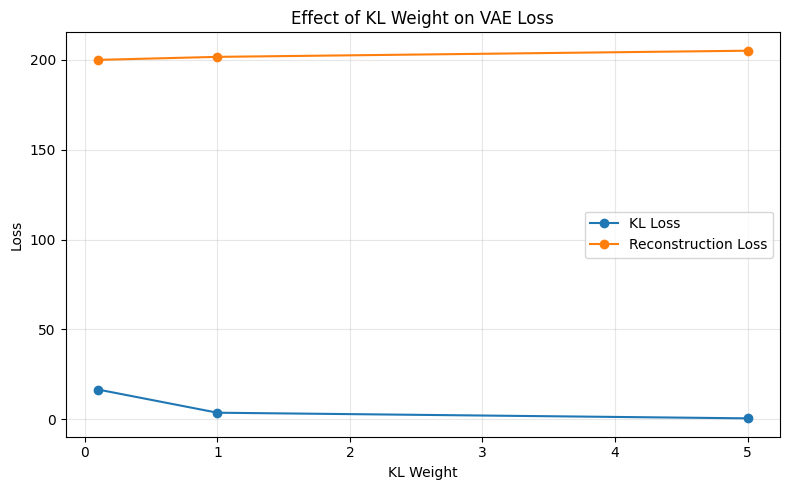

EXERCISE 7 — 50 GENERATED VAE IMAGES


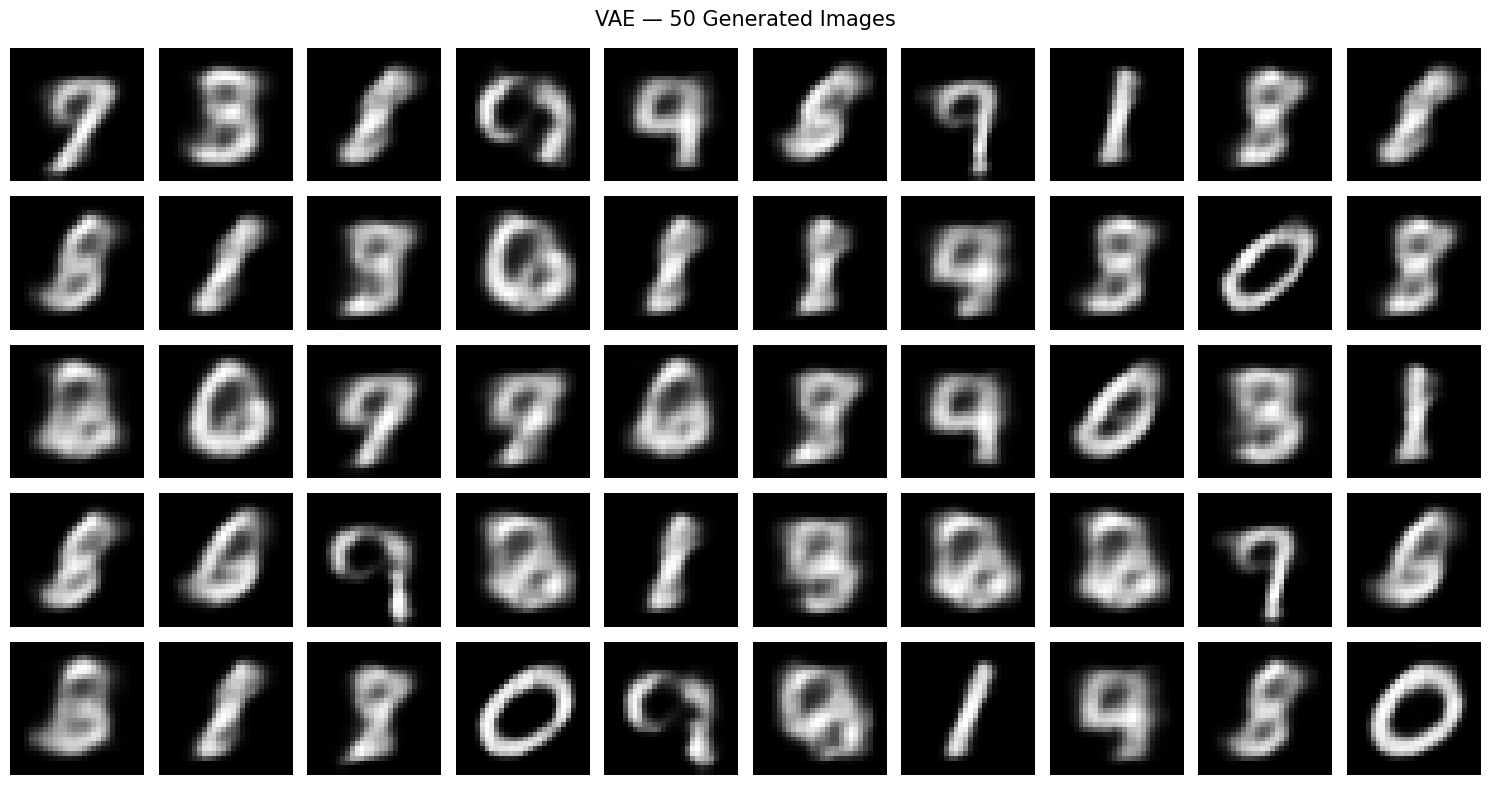

EXERCISE 8 — LATENT INTERPOLATION


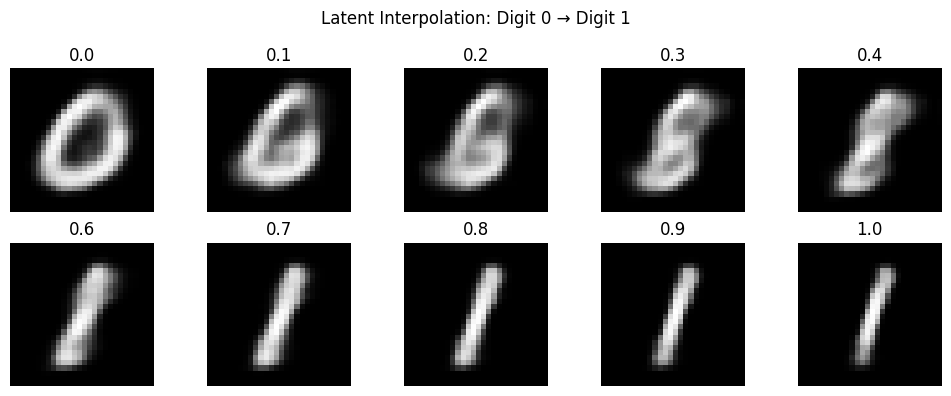

CONSOLIDATED ADDITIONAL EXPERIMENT RESULTS


,Experiment,MSE,MAE,SSIM
0,CAE latent dimension 4,0.050406,0.116350,0.410650
1,CAE latent dimension 8,0.046150,0.106774,0.476621
2,CAE latent dimension 16,0.036355,0.087424,0.588047
3,CAE latent dimension 32,0.032971,0.081303,0.627659
4,Gaussian noise,0.005317,0.023909,0.932470
5,Salt-and-Pepper noise,0.006924,0.027019,0.919692
6,Gaussian sigma 0.1,0.003592,0.018869,0.957262
7,Gaussian sigma 0.3,0.009129,0.032662,0.884445
8,UpSampling decoder,0.007421,0.027869,0.927848
9,Conv2DTranspose decoder,0.009176,0.032197,0.905747



LATEX TABLE — ADDITIONAL EXPERIMENTS
\begin{tabular}{lrrr}
\toprule
Experiment & MSE & MAE & SSIM \\
\midrule
CAE latent dimension 4 & 0.050400 & 0.116300 & 0.410600 \\
CAE latent dimension 8 & 0.046100 & 0.106800 & 0.476600 \\
CAE latent dimension 16 & 0.036400 & 0.087400 & 0.588000 \\
CAE latent dimension 32 & 0.033000 & 0.081300 & 0.627700 \\
Gaussian noise & 0.005300 & 0.023900 & 0.932500 \\
Salt-and-Pepper noise & 0.006900 & 0.027000 & 0.919700 \\
Gaussian sigma 0.1 & 0.003600 & 0.018900 & 0.957300 \\
Gaussian sigma 0.3 & 0.009100 & 0.032700 & 0.884400 \\
UpSampling decoder & 0.007400 & 0.027900 & 0.927800 \\
Conv2DTranspose decoder & 0.009200 & 0.032200 & 0.905700 \\
VAE latent dimension 2 & 0.062400 & 0.141900 & 0.225200 \\
VAE latent dimension 8 & 0.062900 & 0.144400 & 0.206600 \\
VAE KL weight 0.1 & 0.061300 & 0.140200 & 0.225500 \\
VAE KL weight 1 & 0.062000 & 0.143100 & 0.219100 \\
VAE KL weight 5 & 0.062900 & 0.142600 & 0.212400 \\
\bottomrule
\end{tabular}


Excel file sa

In [6]:
# ============================================================
# CELL 4 — ALL ADDITIONAL EXERCISES + FINAL EXPORT
# ============================================================

import os
import time
import zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from tensorflow import keras
from tensorflow.keras import layers
from skimage.metrics import structural_similarity


# ============================================================
# 0. SAFETY / DATA SETUP
# ============================================================

# Make sure output folders exist
os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(TABLE_DIR, exist_ok=True)

# Use smaller datasets for additional experiments
# This keeps Cell 4 reasonably fast.
N_TRAIN_EXTRA = min(5000, len(x_train))
N_TEST_EXTRA = min(1000, len(x_test))

x_train_small = x_train[:N_TRAIN_EXTRA]
x_test_small = x_test[:N_TEST_EXTRA]
y_test_small = y_test[:N_TEST_EXTRA]

print("Additional experiment dataset:")
print("Training samples :", len(x_train_small))
print("Testing samples  :", len(x_test_small))
print()


# ============================================================
# HELPER — SSIM
# ============================================================

def calculate_ssim(
    original,
    reconstructed,
    max_samples=500
):

    n = min(
        max_samples,
        len(original)
    )

    scores = []

    for i in range(n):

        score = structural_similarity(
            original[i].squeeze(),
            reconstructed[i].squeeze(),
            data_range=1.0
        )

        scores.append(score)

    return float(np.mean(scores))


# ============================================================
# HELPER — RECONSTRUCTION METRICS
# ============================================================

def reconstruction_metrics(
    original,
    reconstructed
):

    mse = float(
        np.mean(
            np.square(
                original - reconstructed
            )
        )
    )

    mae = float(
        np.mean(
            np.abs(
                original - reconstructed
            )
        )
    )

    ssim_value = calculate_ssim(
        original,
        reconstructed,
        max_samples=500
    )

    return mse, mae, ssim_value


# ============================================================
# HELPER — QUICK VAE
#
# IMPORTANT:
# This is compatible with the corrected VAE class
# from Cell 3:
#
# VAE(encoder, decoder, beta=...)
# ============================================================

def build_quick_vae(
    latent_dim=2,
    kl_weight=1.0
):

    # --------------------------------------------------------
    # ENCODER
    # --------------------------------------------------------

    encoder_inputs = keras.Input(
        shape=(28, 28, 1),
        name="quick_encoder_input"
    )

    x = layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    )(encoder_inputs)

    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D(2)(x)

    x = layers.Flatten()(x)

    x = layers.Dense(
        128,
        activation="relu"
    )(x)

    z_mean = layers.Dense(
        latent_dim,
        name="z_mean"
    )(x)

    z_log_var = layers.Dense(
        latent_dim,
        name="z_log_var"
    )(x)

    z = Sampling()(
        [z_mean, z_log_var]
    )

    quick_encoder = keras.Model(
        encoder_inputs,
        [z_mean, z_log_var, z],
        name=f"quick_encoder_{latent_dim}"
    )

    # --------------------------------------------------------
    # DECODER
    # --------------------------------------------------------

    latent_inputs = keras.Input(
        shape=(latent_dim,),
        name="quick_decoder_input"
    )

    x = layers.Dense(
        7 * 7 * 64,
        activation="relu"
    )(latent_inputs)

    x = layers.Reshape(
        (7, 7, 64)
    )(x)

    x = layers.Conv2DTranspose(
        64,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    x = layers.Conv2DTranspose(
        32,
        3,
        strides=2,
        padding="same",
        activation="relu"
    )(x)

    decoder_outputs = layers.Conv2DTranspose(
        1,
        3,
        padding="same",
        activation="sigmoid"
    )(x)

    quick_decoder = keras.Model(
        latent_inputs,
        decoder_outputs,
        name=f"quick_decoder_{latent_dim}"
    )

    # --------------------------------------------------------
    # VAE
    # --------------------------------------------------------

    model = VAE(
        quick_encoder,
        quick_decoder,
        beta=kl_weight
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        )
    )

    return (
        model,
        quick_encoder,
        quick_decoder
    )


# ============================================================
# QUICK VAE TRAINING
# ============================================================

def train_quick_vae(
    latent_dim,
    kl_weight=1.0,
    epochs=3
):

    model, enc, dec = build_quick_vae(
        latent_dim=latent_dim,
        kl_weight=kl_weight
    )

    start = time.time()

    history = model.fit(
        x_train_small,
        epochs=epochs,
        batch_size=BATCH_SIZE,
        validation_data=(x_test_small, None),
        verbose=0
    )

    elapsed = time.time() - start

    # --------------------------------------------------------
    # RECONSTRUCTION
    # --------------------------------------------------------

    _, _, z = enc.predict(
        x_test_small,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    reconstructed = dec.predict(
        z,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    mse, mae, ssim_value = reconstruction_metrics(
        x_test_small,
        reconstructed
    )

    return (
        model,
        enc,
        dec,
        history,
        mse,
        mae,
        ssim_value,
        elapsed
    )


# ============================================================
# EXERCISE 1
# CAE LATENT DIMENSION:
# 4, 8, 16, 32
# ============================================================

print("=" * 70)
print("EXERCISE 1 — CAE LATENT DIMENSION")
print("=" * 70)

def build_cae_latent(latent_dim):

    inputs = keras.Input(
        shape=(28, 28, 1)
    )

    x = layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    )(inputs)

    x = layers.MaxPooling2D(2)(x)

    x = layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    )(x)

    x = layers.MaxPooling2D(2)(x)

    # Compress to required latent dimension
    x = layers.Flatten()(x)

    latent = layers.Dense(
        latent_dim,
        activation="relu",
        name="latent"
    )(x)

    x = layers.Dense(
        7 * 7 * 64,
        activation="relu"
    )(latent)

    x = layers.Reshape(
        (7, 7, 64)
    )(x)

    x = layers.UpSampling2D(2)(x)

    x = layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    )(x)

    x = layers.UpSampling2D(2)(x)

    x = layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    )(x)

    outputs = layers.Conv2D(
        1,
        3,
        activation="sigmoid",
        padding="same"
    )(x)

    model = keras.Model(
        inputs,
        outputs,
        name=f"CAE_latent_{latent_dim}"
    )

    model.compile(
        optimizer=keras.optimizers.Adam(
            learning_rate=1e-3
        ),
        loss="binary_crossentropy"
    )

    return model


cae_latent_results = []

cae_latent_models = {}

for d in [4, 8, 16, 32]:

    print(f"Training CAE with latent dimension = {d}")

    model = build_cae_latent(d)

    start = time.time()

    history = model.fit(
        x_train_small,
        x_train_small,
        epochs=3,
        batch_size=BATCH_SIZE,
        validation_data=(
            x_test_small,
            x_test_small
        ),
        verbose=0
    )

    elapsed = time.time() - start

    reconstructed = model.predict(
        x_test_small,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    mse, mae, ssim_value = reconstruction_metrics(
        x_test_small,
        reconstructed
    )

    cae_latent_results.append({
        "Latent Dimension": d,
        "MSE": mse,
        "MAE": mae,
        "SSIM": ssim_value,
        "Training Time (s)": elapsed
    })

    cae_latent_models[d] = model


cae_latent_df = pd.DataFrame(
    cae_latent_results
)

print("\nCAE Latent Dimension Results:")
display(cae_latent_df)

cae_latent_df.to_csv(
    f"{TABLE_DIR}/exercise1_cae_latent_dimension.csv",
    index=False
)


# Plot
plt.figure(figsize=(8, 5))

plt.plot(
    cae_latent_df["Latent Dimension"],
    cae_latent_df["MSE"],
    marker="o"
)

plt.xlabel("Latent Dimension")
plt.ylabel("Reconstruction MSE")
plt.title("CAE Latent Dimension vs Reconstruction MSE")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E1_cae_latent_dimension.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXERCISE 2
# GAUSSIAN VS SALT-AND-PEPPER NOISE
# ============================================================

print("=" * 70)
print("EXERCISE 2 — GAUSSIAN VS SALT-AND-PEPPER NOISE")
print("=" * 70)


def add_salt_pepper_noise(
    images,
    probability=0.1
):

    noisy = images.copy()

    random_values = np.random.rand(
        *images.shape
    )

    noisy[
        random_values < probability / 2
    ] = 0.0

    noisy[
        random_values > 1 - probability / 2
    ] = 1.0

    return noisy


# Gaussian noise
gaussian_test = np.clip(
    x_test_small
    + np.random.normal(
        0,
        0.2,
        x_test_small.shape
    ),
    0,
    1
)

# Salt and pepper
sp_test = add_salt_pepper_noise(
    x_test_small,
    probability=0.1
)


# Train DAE on Gaussian noise
dae_gaussian = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(2),

    layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    ),

    layers.UpSampling2D(2),

    layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        1,
        3,
        activation="sigmoid",
        padding="same"
    )
])

dae_gaussian.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

gaussian_train = np.clip(
    x_train_small
    + np.random.normal(
        0,
        0.2,
        x_train_small.shape
    ),
    0,
    1
)

dae_gaussian.fit(
    gaussian_train,
    x_train_small,
    epochs=3,
    batch_size=BATCH_SIZE,
    verbose=0
)

gaussian_denoised = dae_gaussian.predict(
    gaussian_test,
    batch_size=BATCH_SIZE,
    verbose=0
)


# Train DAE on Salt-Pepper noise
dae_sp = keras.Sequential([
    layers.Input(shape=(28, 28, 1)),

    layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(2),

    layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    ),

    layers.UpSampling2D(2),

    layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        1,
        3,
        activation="sigmoid",
        padding="same"
    )
])

dae_sp.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

sp_train = add_salt_pepper_noise(
    x_train_small,
    probability=0.1
)

dae_sp.fit(
    sp_train,
    x_train_small,
    epochs=3,
    batch_size=BATCH_SIZE,
    verbose=0
)

sp_denoised = dae_sp.predict(
    sp_test,
    batch_size=BATCH_SIZE,
    verbose=0
)


# Metrics
g_mse, g_mae, g_ssim = reconstruction_metrics(
    x_test_small,
    gaussian_denoised
)

sp_mse, sp_mae, sp_ssim = reconstruction_metrics(
    x_test_small,
    sp_denoised
)

noise_type_df = pd.DataFrame({
    "Noise Type": [
        "Gaussian",
        "Salt-and-Pepper"
    ],
    "MSE": [
        g_mse,
        sp_mse
    ],
    "MAE": [
        g_mae,
        sp_mae
    ],
    "SSIM": [
        g_ssim,
        sp_ssim
    ]
})

print("\nNoise Type Comparison:")
display(noise_type_df)

noise_type_df.to_csv(
    f"{TABLE_DIR}/exercise2_noise_type_comparison.csv",
    index=False
)


# Plot
plt.figure(figsize=(8, 5))

x_pos = np.arange(2)

plt.bar(
    x_pos,
    noise_type_df["SSIM"]
)

plt.xticks(
    x_pos,
    noise_type_df["Noise Type"]
)

plt.ylabel("SSIM")
plt.title("Gaussian vs Salt-and-Pepper Noise")
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E2_gaussian_vs_salt_pepper.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXERCISE 3
# COMPARE TWO NOISE LEVELS
# ============================================================

print("=" * 70)
print("EXERCISE 3 — TWO NOISE LEVELS")
print("=" * 70)

noise_level_results = []

for sigma in [0.1, 0.3]:

    noisy_train = np.clip(
        x_train_small
        + np.random.normal(
            0,
            sigma,
            x_train_small.shape
        ),
        0,
        1
    )

    noisy_test = np.clip(
        x_test_small
        + np.random.normal(
            0,
            sigma,
            x_test_small.shape
        ),
        0,
        1
    )

    model = keras.Sequential([
        layers.Input(
            shape=(28, 28, 1)
        ),

        layers.Conv2D(
            32,
            3,
            activation="relu",
            padding="same"
        ),

        layers.MaxPooling2D(2),

        layers.Conv2D(
            64,
            3,
            activation="relu",
            padding="same"
        ),

        layers.UpSampling2D(2),

        layers.Conv2D(
            32,
            3,
            activation="relu",
            padding="same"
        ),

        layers.Conv2D(
            1,
            3,
            activation="sigmoid",
            padding="same"
        )
    ])

    model.compile(
        optimizer="adam",
        loss="binary_crossentropy"
    )

    model.fit(
        noisy_train,
        x_train_small,
        epochs=3,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    denoised = model.predict(
        noisy_test,
        batch_size=BATCH_SIZE,
        verbose=0
    )

    mse, mae, ssim_value = reconstruction_metrics(
        x_test_small,
        denoised
    )

    noise_level_results.append({
        "Noise Sigma": sigma,
        "MSE": mse,
        "MAE": mae,
        "SSIM": ssim_value
    })


noise_level_df = pd.DataFrame(
    noise_level_results
)

print("\nTwo Noise Level Results:")
display(noise_level_df)

noise_level_df.to_csv(
    f"{TABLE_DIR}/exercise3_two_noise_levels.csv",
    index=False
)


plt.figure(figsize=(8, 5))

plt.plot(
    noise_level_df["Noise Sigma"],
    noise_level_df["SSIM"],
    marker="o"
)

plt.xlabel("Gaussian Noise Sigma")
plt.ylabel("SSIM")
plt.title("Noise Level vs Reconstruction Quality")
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E3_noise_level_vs_quality.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXERCISE 4
# UPSAMPLING VS CONV2DTRANSPOSE DECODER
# ============================================================

print("=" * 70)
print("EXERCISE 4 — UPSAMPLING VS CONV2DTRANSPOSE")
print("=" * 70)


# ------------------------------------------------------------
# Model A — Upsampling decoder
# ------------------------------------------------------------

upsampling_model = keras.Sequential([

    layers.Input(
        shape=(28, 28, 1)
    ),

    layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(2),

    layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(2),

    layers.UpSampling2D(2),

    layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    ),

    layers.UpSampling2D(2),

    layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    ),

    layers.Conv2D(
        1,
        3,
        activation="sigmoid",
        padding="same"
    )
])

upsampling_model.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

start = time.time()

upsampling_model.fit(
    x_train_small,
    x_train_small,
    epochs=3,
    batch_size=BATCH_SIZE,
    verbose=0
)

upsampling_time = time.time() - start

upsampling_recon = upsampling_model.predict(
    x_test_small,
    batch_size=BATCH_SIZE,
    verbose=0
)

up_mse, up_mae, up_ssim = reconstruction_metrics(
    x_test_small,
    upsampling_recon
)


# ------------------------------------------------------------
# Model B — Conv2DTranspose decoder
# ------------------------------------------------------------

transpose_model = keras.Sequential([

    layers.Input(
        shape=(28, 28, 1)
    ),

    layers.Conv2D(
        32,
        3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(2),

    layers.Conv2D(
        64,
        3,
        activation="relu",
        padding="same"
    ),

    layers.MaxPooling2D(2),

    layers.Conv2DTranspose(
        64,
        3,
        strides=2,
        padding="same",
        activation="relu"
    ),

    layers.Conv2DTranspose(
        32,
        3,
        strides=2,
        padding="same",
        activation="relu"
    ),

    layers.Conv2D(
        1,
        3,
        activation="sigmoid",
        padding="same"
    )
])

transpose_model.compile(
    optimizer="adam",
    loss="binary_crossentropy"
)

start = time.time()

transpose_model.fit(
    x_train_small,
    x_train_small,
    epochs=3,
    batch_size=BATCH_SIZE,
    verbose=0
)

transpose_time = time.time() - start

transpose_recon = transpose_model.predict(
    x_test_small,
    batch_size=BATCH_SIZE,
    verbose=0
)

tr_mse, tr_mae, tr_ssim = reconstruction_metrics(
    x_test_small,
    transpose_recon
)


decoder_comparison_df = pd.DataFrame({

    "Decoder": [
        "UpSampling2D + Conv2D",
        "Conv2DTranspose"
    ],

    "MSE": [
        up_mse,
        tr_mse
    ],

    "MAE": [
        up_mae,
        tr_mae
    ],

    "SSIM": [
        up_ssim,
        tr_ssim
    ],

    "Training Time (s)": [
        upsampling_time,
        transpose_time
    ]
})

print("\nDecoder Comparison:")
display(decoder_comparison_df)

decoder_comparison_df.to_csv(
    f"{TABLE_DIR}/exercise4_decoder_comparison.csv",
    index=False
)


# Plot
plt.figure(figsize=(8, 5))

plt.bar(
    decoder_comparison_df["Decoder"],
    decoder_comparison_df["SSIM"]
)

plt.ylabel("SSIM")
plt.title("UpSampling vs Conv2DTranspose Decoder")
plt.xticks(rotation=10)
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E4_decoder_comparison.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXERCISE 5
# VAE LATENT DIMENSION 2 VS 8
# ============================================================

print("=" * 70)
print("EXERCISE 5 — VAE LATENT DIMENSION 2 VS 8")
print("=" * 70)

vae_latent_results = {}
vae_latent_models = {}

for d in [2, 8]:

    print(
        f"Training VAE with latent dimension = {d}"
    )

    (
        model,
        enc,
        dec,
        history,
        mse,
        mae,
        ssim_value,
        elapsed
    ) = train_quick_vae(
        latent_dim=d,
        kl_weight=1.0,
        epochs=3
    )

    vae_latent_models[d] = (
        model,
        enc,
        dec,
        history
    )

    vae_latent_results[d] = {
        "Latent Dimension": d,
        "MSE": mse,
        "MAE": mae,
        "SSIM": ssim_value,
        "Training Time (s)": elapsed
    }


vae_latent_df = pd.DataFrame(
    list(vae_latent_results.values())
)

print("\nVAE Latent Dimension Results:")
display(vae_latent_df)

vae_latent_df.to_csv(
    f"{TABLE_DIR}/exercise5_vae_latent_2_vs_8.csv",
    index=False
)


plt.figure(figsize=(7, 5))

plt.bar(
    vae_latent_df["Latent Dimension"].astype(str),
    vae_latent_df["SSIM"]
)

plt.xlabel("Latent Dimension")
plt.ylabel("SSIM")
plt.title("VAE Latent Dimension 2 vs 8")
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E5_vae_latent_2_vs_8.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXERCISE 6
# KL LOSS CONTRIBUTION
# KL WEIGHTS = 0.1, 1, 5
# ============================================================

print("=" * 70)
print("EXERCISE 6 — KL LOSS CONTRIBUTION")
print("=" * 70)

kl_results = []

kl_models = {}

for weight in [0.1, 1.0, 5.0]:

    print(
        f"Training VAE with KL weight = {weight}"
    )

    (
        model,
        enc,
        dec,
        history,
        mse,
        mae,
        ssim_value,
        elapsed
    ) = train_quick_vae(
        latent_dim=2,
        kl_weight=weight,
        epochs=3
    )

    kl_models[weight] = (
        model,
        enc,
        dec,
        history
    )

    kl_results.append({

        "KL Weight": weight,

        "Final Total Loss":
            history.history["loss"][-1],

        "Final Reconstruction Loss":
            history.history["reconstruction_loss"][-1],

        "Final KL Loss":
            history.history["kl_loss"][-1],

        "MSE": mse,

        "MAE": mae,

        "SSIM": ssim_value,

        "Training Time (s)": elapsed
    })


kl_df = pd.DataFrame(
    kl_results
)

print("\nKL Weight Results:")
display(kl_df)

kl_df.to_csv(
    f"{TABLE_DIR}/exercise6_kl_loss_contribution.csv",
    index=False
)


# Plot KL loss
plt.figure(figsize=(8, 5))

plt.plot(
    kl_df["KL Weight"],
    kl_df["Final KL Loss"],
    marker="o",
    label="KL Loss"
)

plt.plot(
    kl_df["KL Weight"],
    kl_df["Final Reconstruction Loss"],
    marker="o",
    label="Reconstruction Loss"
)

plt.xlabel("KL Weight")
plt.ylabel("Loss")
plt.title("Effect of KL Weight on VAE Loss")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E6_kl_loss_contribution.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXERCISE 7
# GENERATE LARGER VAE SAMPLE GRID — 50 IMAGES
# ============================================================

print("=" * 70)
print("EXERCISE 7 — 50 GENERATED VAE IMAGES")
print("=" * 70)

# Use the main VAE from Cell 3
n_samples = 50

random_latent = np.random.normal(
    size=(n_samples, latent_dim)
)

large_generated_images = decoder.predict(
    random_latent,
    verbose=0
)


fig, axes = plt.subplots(
    5,
    10,
    figsize=(15, 8)
)

for i, ax in enumerate(
    axes.flat
):

    ax.imshow(
        large_generated_images[i].squeeze(),
        cmap="gray"
    )

    ax.axis("off")

plt.suptitle(
    "VAE — 50 Generated Images",
    fontsize=15
)

plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E7_50_generated_images.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# EXERCISE 8
# LATENT INTERPOLATION BETWEEN TWO DIGIT REGIONS
# ============================================================

print("=" * 70)
print("EXERCISE 8 — LATENT INTERPOLATION")
print("=" * 70)

# Find one digit 0 and one digit 1
digit_a = 0
digit_b = 1

idx_a = np.where(
    y_test == digit_a
)[0][0]

idx_b = np.where(
    y_test == digit_b
)[0][0]

z_a = z_mean_test[
    idx_a
]

z_b = z_mean_test[
    idx_b
]

n_steps = 10

interpolation_values = np.linspace(
    0,
    1,
    n_steps
)

interpolated_z = np.array([

    z_a
    + alpha * (z_b - z_a)

    for alpha in interpolation_values

])

interpolated_images = decoder.predict(
    interpolated_z,
    verbose=0
)


fig, axes = plt.subplots(
    2,
    5,
    figsize=(10, 4)
)

for i, ax in enumerate(
    axes.flat
):

    ax.imshow(
        interpolated_images[i].squeeze(),
        cmap="gray"
    )

    ax.set_title(
        f"{interpolation_values[i]:.1f}"
    )

    ax.axis("off")

plt.suptitle(
    f"Latent Interpolation: Digit {digit_a} → Digit {digit_b}"
)

plt.tight_layout()

plt.savefig(
    f"{GRAPH_DIR}/E8_latent_interpolation_0_to_1.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()


# ============================================================
# FINAL CONSOLIDATED ADDITIONAL-EXPERIMENT TABLE
# ============================================================

print("=" * 70)
print("CONSOLIDATED ADDITIONAL EXPERIMENT RESULTS")
print("=" * 70)

consolidated_extra = pd.DataFrame({

    "Experiment": [
        "CAE latent dimension 4",
        "CAE latent dimension 8",
        "CAE latent dimension 16",
        "CAE latent dimension 32",
        "Gaussian noise",
        "Salt-and-Pepper noise",
        "Gaussian sigma 0.1",
        "Gaussian sigma 0.3",
        "UpSampling decoder",
        "Conv2DTranspose decoder",
        "VAE latent dimension 2",
        "VAE latent dimension 8",
        "VAE KL weight 0.1",
        "VAE KL weight 1",
        "VAE KL weight 5"
    ],

    "MSE": [

        *cae_latent_df["MSE"].tolist(),

        g_mse,
        sp_mse,

        noise_level_df.iloc[0]["MSE"],
        noise_level_df.iloc[1]["MSE"],

        up_mse,
        tr_mse,

        vae_latent_df[
            vae_latent_df["Latent Dimension"] == 2
        ]["MSE"].iloc[0],

        vae_latent_df[
            vae_latent_df["Latent Dimension"] == 8
        ]["MSE"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 0.1
        ]["MSE"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 1.0
        ]["MSE"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 5.0
        ]["MSE"].iloc[0]
    ],

    "MAE": [

        *cae_latent_df["MAE"].tolist(),

        g_mae,
        sp_mae,

        noise_level_df.iloc[0]["MAE"],
        noise_level_df.iloc[1]["MAE"],

        up_mae,
        tr_mae,

        vae_latent_df[
            vae_latent_df["Latent Dimension"] == 2
        ]["MAE"].iloc[0],

        vae_latent_df[
            vae_latent_df["Latent Dimension"] == 8
        ]["MAE"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 0.1
        ]["MAE"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 1.0
        ]["MAE"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 5.0
        ]["MAE"].iloc[0]
    ],

    "SSIM": [

        *cae_latent_df["SSIM"].tolist(),

        g_ssim,
        sp_ssim,

        noise_level_df.iloc[0]["SSIM"],
        noise_level_df.iloc[1]["SSIM"],

        up_ssim,
        tr_ssim,

        vae_latent_df[
            vae_latent_df["Latent Dimension"] == 2
        ]["SSIM"].iloc[0],

        vae_latent_df[
            vae_latent_df["Latent Dimension"] == 8
        ]["SSIM"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 0.1
        ]["SSIM"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 1.0
        ]["SSIM"].iloc[0],

        kl_df[
            kl_df["KL Weight"] == 5.0
        ]["SSIM"].iloc[0]
    ]
})

display(consolidated_extra)

consolidated_extra.to_csv(
    f"{TABLE_DIR}/additional_experiments_consolidated.csv",
    index=False
)


# ============================================================
# LATEX TABLE OUTPUT
# ============================================================

print("\n" + "=" * 70)
print("LATEX TABLE — ADDITIONAL EXPERIMENTS")
print("=" * 70)

print(
    consolidated_extra.round(4).to_latex(
        index=False
    )
)


# ============================================================
# SAVE ALL ADDITIONAL DATA INTO EXCEL
# ============================================================

excel_path = (
    f"{TABLE_DIR}/Experiment7_All_Additional_Results.xlsx"
)

with pd.ExcelWriter(
    excel_path,
    engine="openpyxl"
) as writer:

    cae_latent_df.to_excel(
        writer,
        sheet_name="E1_CAE_Latent",
        index=False
    )

    noise_type_df.to_excel(
        writer,
        sheet_name="E2_Noise_Type",
        index=False
    )

    noise_level_df.to_excel(
        writer,
        sheet_name="E3_Noise_Levels",
        index=False
    )

    decoder_comparison_df.to_excel(
        writer,
        sheet_name="E4_Decoder",
        index=False
    )

    vae_latent_df.to_excel(
        writer,
        sheet_name="E5_VAE_Latent",
        index=False
    )

    kl_df.to_excel(
        writer,
        sheet_name="E6_KL_Weight",
        index=False
    )

    consolidated_extra.to_excel(
        writer,
        sheet_name="Consolidated",
        index=False
    )

print(
    f"\nExcel file saved:\n{excel_path}"
)


# ============================================================
# CREATE ZIP OF ENTIRE EXPERIMENT 7 RESULTS
# ============================================================

zip_path = "/content/Experiment7_All_Results.zip"

# Remove old ZIP if it exists
if os.path.exists(zip_path):
    os.remove(zip_path)

with zipfile.ZipFile(
    zip_path,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    for root, dirs, files in os.walk(
        "/content/experiment7_results"
    ):

        for file in files:

            full_path = os.path.join(
                root,
                file
            )

            arcname = os.path.relpath(
                full_path,
                "/content"
            )

            zipf.write(
                full_path,
                arcname
            )


# ============================================================
# FINAL SUMMARY
# ============================================================

print("\n" + "=" * 70)
print("EXPERIMENT 7 — ALL RESULTS COMPLETED")
print("=" * 70)

print("\nGraphs folder:")
print(
    "/content/experiment7_results/graphs/"
)

print("\nTables folder:")
print(
    "/content/experiment7_results/tables/"
)

print("\nExcel file:")
print(
    excel_path
)

print("\nZIP file:")
print(
    zip_path
)

print("\nSaved graph files:")

for filename in sorted(
    os.listdir(GRAPH_DIR)
):

    if filename.endswith(".png"):
        print("  ✓", filename)

print(
    f"\nTotal plots currently saved: "
    f"{len([f for f in os.listdir(GRAPH_DIR) if f.endswith('.png')])}"
)

print("\nAll additional experiments completed successfully.")